# Experiment #8: Naive Bayes Spam Message Classifier

**Dataset:** SMS Spam Collection (`spam.csv`) - 5,572 messages labelled spam / ham  
**Name:** Adithya Rajesh  |  **Class:** R3AI  |  **Roll No:** B25CTA07  |  **Date:** 13-10-2026

**Objective:** An email/SMS service provider wants to automatically detect **spam** messages. We preprocess the text data, convert it into numeric vectors, and train a **Multinomial Naive Bayes** classifier to distinguish **spam (1)** from **ham (0)**. The model is evaluated using a confusion matrix heatmap plus accuracy, precision, recall and F1-score.

> **Note:** The notebook must stay in the same folder as `spam.csv`.


## 1. Import the Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

## 2. Load the Dataset and Inspect It

The raw file uses a `latin-1` encoding and contains three empty trailing columns (`Unnamed: 2/3/4`) left over from the CSV export. `v1` holds the label and `v2` holds the message text.


In [2]:
df = pd.read_csv('spam.csv', encoding='latin-1')

print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()

Shape: (5572, 5)
Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
print('Missing values per column:')
print(df.isna().sum())
print()
print('Class label counts (before mapping):')
print(df['v1'].value_counts())

Missing values per column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Class label counts (before mapping):
v1
ham     4825
spam     747
Name: count, dtype: int64


## 3. Handle Missing / Inconsistent Data and Encode the Labels

- Drop the empty `Unnamed` columns and rename `v1`, `v2` to meaningful names.
- Map the labels to numbers: **spam -> 1**, **ham -> 0**.
- Remove **null values** and **duplicate** records.


In [4]:
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])
df = df.rename(columns={'v1': 'Category', 'v2': 'Message'})

df['Category'] = df['Category'].map({'spam': 1, 'ham': 0})

print('Null values before cleaning:', df.isna().sum().sum())
print('Duplicate rows          :', df.duplicated().sum())

before = df.shape[0]
df = df.dropna().drop_duplicates()
print(f'Rows removed as null/duplicate: {before - df.shape[0]}')
print('Cleaned shape:', df.shape)
print()
print('Class balance after cleaning:')
print(df['Category'].value_counts())

Null values before cleaning: 0
Duplicate rows          : 403
Rows removed as null/duplicate: 403
Cleaned shape: (5169, 2)

Class balance after cleaning:
Category
0    4516
1     653
Name: count, dtype: int64


## 4. Transform the Message Text into Vector Representations

Text cannot be fed directly to a classifier. We use **CountVectorizer**, which builds a vocabulary of all words and represents each message as a vector of **word counts** (the classic representation for Multinomial Naive Bayes).


In [5]:
vectorizer = CountVectorizer()

X = vectorizer.fit_transform(df['Message'])
y = df['Category']

print('Vocabulary size           :', len(vectorizer.vocabulary_))
print('Vectorised matrix shape   :', X.shape)

Vocabulary size           : 8672
Vectorised matrix shape   : (5169, 8672)


## 5. Split the Dataset into Training (80%) and Testing (20%) Sets

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=16, stratify=y)

print('Training set:', X_train.shape)
print('Test set:    ', X_test.shape)

Training set: (4135, 8672)
Test set:     (1034, 8672)


## 6. Train the Multinomial Naive Bayes Classifier

In [7]:
model = MultinomialNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print('Model trained successfully')
print('Test samples predicted:', len(y_pred))

Model trained successfully
Test samples predicted: 1034


## 7. Evaluate the Model

We report the **confusion matrix** (as a heatmap) and the **accuracy, precision, recall and F1-score**.


Confusion Matrix:
[[887  16]
 [ 10 121]]


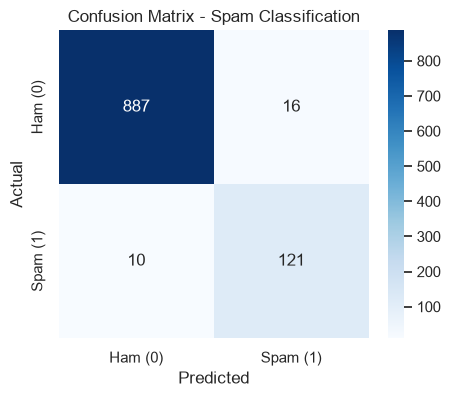

In [8]:
cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham (0)', 'Spam (1)'],
            yticklabels=['Ham (0)', 'Spam (1)'])
plt.title('Confusion Matrix - Spam Classification')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [9]:
print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print('F1-score :', round(f1_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

Accuracy : 0.9749
Precision: 0.8832
Recall   : 0.9237
F1-score : 0.903

              precision    recall  f1-score   support

         Ham       0.99      0.98      0.99       903
        Spam       0.88      0.92      0.90       131

    accuracy                           0.97      1034
   macro avg       0.94      0.95      0.94      1034
weighted avg       0.98      0.97      0.98      1034



## 8. Classify Unseen Messages

We can now use the trained model to classify brand-new messages. Each message is transformed with the **same** vectorizer before prediction.


In [10]:
new_messages = [
    'Congratulations! You have won a free iPhone. Call now to claim your prize.',
    'Hey, are we still meeting for lunch tomorrow?'
]

new_vectors = vectorizer.transform(new_messages)
predictions = model.predict(new_vectors)

for msg, pred in zip(new_messages, predictions):
    label = 'SPAM' if pred == 1 else 'HAM'
    print(f'[{label}] {msg}')

[SPAM] Congratulations! You have won a free iPhone. Call now to claim your prize.
[HAM] Hey, are we still meeting for lunch tomorrow?


---
## Inference & Analysis

- The dataset was cleaned by removing the empty `Unnamed` columns, converting **spam -> 1 / ham -> 0**, and dropping **null and duplicate** rows (403 duplicates removed), leaving a balanced-enough set of messages.
- **CountVectorizer** turned the raw text into a sparse **bag-of-words** matrix (vocabulary of ~8,600 words), which is the ideal input for Multinomial Naive Bayes.
- After an **80/20 stratified split**, the Multinomial Naive Bayes classifier achieved an **accuracy of about 0.975**. The spam class scored a **precision of ~0.88**, **recall of ~0.92** and **F1-score of ~0.90**, while ham was classified almost perfectly.
- The confusion matrix shows only a handful of misclassifications, and the trained model correctly flags a promotional test message as **SPAM** and a normal chat message as **HAM** - demonstrating a working spam filter.

---
**End of Experiment #8.**
